In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import pprint

import seaborn as sns
sns.set_theme(style='whitegrid', font_scale=1.3, palette=sns.color_palette(),)
import matplotlib.pyplot as plt
import duckdb
import polars as pl
import numpy as np
import hydra
from omegaconf import OmegaConf
import numpy as np
import jax

import conf.conf
import userfm.datasets
import userfm.event_constraints
import userfm.plots
import userfm.utils

/home/ttransue/GitHub/RpCN-Dynamical-Systems/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
os.environ['CUDA_VISIBLE_DEVICES'] = ''

In [4]:
duckdb.sql("""
attach '../runs.sqlite';
use runs;
""")

# Dynamical system

### Lorenz '63

In [5]:
dataset_name = 'Lorenz63'
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join Lorenz63 on DynamicalSystem.id = Lorenz63.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 90
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

┌────────────┬───────────────────┬─────────────────┬──────────────────┬───┬────────────────────┬───────────┬───────┐
│ batch_size │ batch_count_train │ batch_count_val │ batch_count_test │ … │        beta        │ rescaling │  id   │
│   int64    │       int64       │      int64      │      int64       │   │       double       │  double   │ int64 │
├────────────┼───────────────────┼─────────────────┼──────────────────┼───┼────────────────────┼───────────┼───────┤
│        500 │                 0 │               0 │                0 │ … │ 2.6666666666666665 │      20.0 │     4 │
├────────────┴───────────────────┴─────────────────┴──────────────────┴───┴────────────────────┴───────────┴───────┤
│ 1 rows                                                                                      16 columns (7 shown) │
└──────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



### FitzHugh-Nagumo

In [43]:
dataset_name = 'FitzHughNagumo'
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join FitzHughNagumo on DynamicalSystem.id = FitzHughNagumo.id
where true
and batch_count_train = 0
and batch_count_val = 0
and batch_count_test = 0
and time_step_count = 310
""")
dataset_rows.show(max_width=120)
assert len(dataset_rows) == 1

┌────────────┬───────────────────┬─────────────────┬──────────────────┬───┬────────┬────────────┬────────────┬───────┐
│ batch_size │ batch_count_train │ batch_count_val │ batch_count_test │ … │   k    │ coupling12 │ coupling21 │  id   │
│   int64    │       int64       │      int64      │      int64       │   │ double │   double   │   double   │ int64 │
├────────────┼───────────────────┼─────────────────┼──────────────────┼───┼────────┼────────────┼────────────┼───────┤
│        500 │                 0 │               0 │                0 │ … │  0.128 │        1.0 │        1.0 │     5 │
├────────────┴───────────────────┴─────────────────┴──────────────────┴───┴────────┴────────────┴────────────┴───────┤
│ 1 rows                                                                                        21 columns (8 shown) │
└────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



# Model

### Probability path

##### Conditional optimal transport

In [ ]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join ConditionalOT on ProbabilityPath.id = ConditionalOT.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

##### Variance exploding

In [44]:
probability_path_rows = duckdb.sql("""
select
    *
from ProbabilityPath
join VarianceExploding on ProbabilityPath.id = VarianceExploding.id
""")
probability_path_rows.show()
assert len(probability_path_rows) == 1

┌───────────────────┬───────┬──────────┬───────────┬───────────┬────────────────────────┬───────┐
│  sa_inheritance   │  id   │ time_min │ sigma_min │ sigma_max │ finzi_karras_weighting │  id   │
│      varchar      │ int64 │  double  │  double   │  double   │         int64          │ int64 │
├───────────────────┼───────┼──────────┼───────────┼───────────┼────────────────────────┼───────┤
│ VarianceExploding │     1 │    0.001 │     0.001 │     300.0 │                      1 │     1 │
└───────────────────┴───────┴──────────┴───────────┴───────────┴────────────────────────┴───────┘



### Steering

##### No steering

In [7]:
no_steering_rows = duckdb.sql("""
select
    *
from Steering
join NoSteering on Steering.id = NoSteering.id
where true
and batch_count = 64
and sampling_step_count = 100
""")
no_steering_rows.show()

┌─────────────┬─────────────────────┬────────────────┬───────┬────────────────────┬─────────────────────────┬───────┬────────────────┐
│ batch_count │ sampling_step_count │ sa_inheritance │  id   │ penalization_power │ symmetric_binary_reward │  id   │     solver     │
│    int64    │        int64        │    varchar     │ int64 │       double       │          int64          │ int64 │    varchar     │
├─────────────┼─────────────────────┼────────────────┼───────┼────────────────────┼─────────────────────────┼───────┼────────────────┤
│          64 │                 100 │ NoSteering     │     5 │                0.0 │                       1 │     5 │ HEUN           │
│          64 │                 100 │ NoSteering     │   309 │                0.0 │                       1 │   309 │ EULER_MARUYAMA │
└─────────────┴─────────────────────┴────────────────┴───────┴────────────────────┴─────────────────────────┴───────┴────────────────┘



##### Source parallel tempering

In [10]:
spt_steering_rows = duckdb.sql("""
select
    *
from Steering
join SourceParallelTempering on Steering.id = SourceParallelTempering.id
join BestSPTParameter on (
    SourceParallelTempering.update_count = BestSPTParameter.update_count
    and
    SourceParallelTempering.chain_count = BestSPTParameter.chain_count
)
join SweepTrainedModel on (
    SourceParallelTempering.tilt = SweepTrainedModel.tilt
    and
    BestSPTParameter.dynamical_system = SweepTrainedModel.dynamical_system
)
where true
and symmetric_binary_reward
""")
spt_steering_rows.show(max_width=120)

┌─────────────┬─────────────────────┬──────────────────────┬───┬──────────────┬──────────────────┬────────┐
│ batch_count │ sampling_step_count │    sa_inheritance    │ … │ model_alt_id │ dynamical_system │  tilt  │
│    int64    │        int64        │       varchar        │   │   varchar    │     varchar      │ double │
├─────────────┼─────────────────────┼──────────────────────┼───┼──────────────┼──────────────────┼────────┤
│          64 │                 100 │ SourceParallelTemp…  │ … │ o53qnpz8     │ Lorenz63         │   8.29 │
│          64 │                 100 │ SourceParallelTemp…  │ … │ aezlb9vb     │ FitzHughNagumo   │  10.27 │
│          64 │                 100 │ SourceParallelTemp…  │ … │ amh4m6kc     │ Lorenz63         │   8.29 │
│          64 │                 100 │ SourceParallelTemp…  │ … │ rn8n5ie5     │ FitzHughNagumo   │  10.27 │
│          64 │                 100 │ SourceParallelTemp…  │ … │ esvulji4     │ Lorenz63         │   8.29 │
│          64 │             

##### Feynmann-Kac

In [45]:
fk_steering_rows = duckdb.sql("""
select
    *
from Steering
join FeynmannKac on Steering.id = FeynmannKac.id
join FeynmannKacIntermediateReward on FeynmannKac.FeynmannKacIntermediateReward = FeynmannKacIntermediateReward.id
join FeynmannKacIntermediateRewardExpectedSample on FeynmannKacIntermediateReward.id = FeynmannKacIntermediateRewardExpectedSample.id
join BestFKParameter on (
    FeynmannKac.potential = BestFKParameter.potential
    and
    FeynmannKac.ensemble_size = BestFKParameter.ensemble_size
    and
    Steering.penalization_power = BestFKParameter.penalization_power
)
join SweepModelTrained using (tilt, dynamical_system)
where true
and symmetric_binary_reward
and Steering.penalization_power = 0
""")
fk_steering_rows#.show(max_width=120)

┌─────────────┬─────────────────────┬────────────────┬───────┬────────────────────┬─────────────────────────┬───────────────┬────────────┬────────┬───────┬───────────────────────────────┬─────────────────────────────────────────────┬───────┬───────┬──────────────────┬────────────┬───────────────┬────────────────────┬──────────────┐
│ batch_count │ sampling_step_count │ sa_inheritance │  id   │ penalization_power │ symmetric_binary_reward │ ensemble_size │ potential  │  tilt  │  id   │ FeynmannKacIntermediateReward │               sa_inheritance                │  id   │  id   │ dynamical_system │ potential  │ ensemble_size │ penalization_power │ model_alt_id │
│    int64    │        int64        │    varchar     │ int64 │       double       │          int64          │     int64     │  varchar   │ double │ int64 │             int64             │                   varchar                   │ int64 │ int64 │     varchar      │  varchar   │     int64     │       double       │   varchar    

##### RpCN

In [46]:
rpcn_steering_rows = duckdb.sql("""
select
    *
from Steering
join RpCN on Steering.id = RpCN.id
join BestRpCNParameter using (pcn_update_count, chain_count)
join SweepModelTrained using (tilt, dynamical_system)
where true
and symmetric_binary_reward
""")
rpcn_steering_rows

┌─────────────┬─────────────────────┬────────────────┬───────┬────────────────────┬─────────────────────────┬─────────────┬──────────────────┬────────┬───────┬───────────────────────────────┬──────────────────┬────────────────────┬──────────────┐
│ batch_count │ sampling_step_count │ sa_inheritance │  id   │ penalization_power │ symmetric_binary_reward │ chain_count │ pcn_update_count │  tilt  │  id   │ FeynmannKacIntermediateReward │ dynamical_system │ penalization_power │ model_alt_id │
│    int64    │        int64        │    varchar     │ int64 │       double       │          int64          │    int64    │      int64       │ double │ int64 │             int64             │     varchar      │       double       │   varchar    │
├─────────────┼─────────────────────┼────────────────┼───────┼────────────────────┼─────────────────────────┼─────────────┼──────────────────┼────────┼───────┼───────────────────────────────┼──────────────────┼────────────────────┼──────────────┤
│          6

### Model

In [47]:
model_rows = duckdb.sql("""
select
    *
from Model
join FlowMatching on Model.id = FlowMatching.id
join probability_path_rows on FlowMatching.ProbabilityPath = probability_path_rows.id
""")
model_rows.show(max_width=120)

┌────────────────┬───────┬─────────────┬────────┬───┬──────────┬───────────┬───────────┬──────────────────────┬───────┐
│ sa_inheritance │  id   │ epoch_count │   lr   │ … │ time_min │ sigma_min │ sigma_max │ finzi_karras_weigh…  │ id_1  │
│    varchar     │ int64 │    int64    │ double │   │  double  │  double   │  double   │        int64         │ int64 │
├────────────────┼───────┼─────────────┼────────┼───┼──────────┼───────────┼───────────┼──────────────────────┼───────┤
│ FlowMatching   │     1 │        2000 │ 0.0001 │ … │    0.001 │     0.001 │     300.0 │                    1 │     1 │
├────────────────┴───────┴─────────────┴────────┴───┴──────────┴───────────┴───────────┴──────────────────────┴───────┤
│ 1 rows                                                                                         17 columns (9 shown) │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘



# Rows

In [48]:
rows = duckdb.sql("""
select
    Conf.alt_id,
    steering_rows.*,
    dataset_rows.batch_size,
from Conf
join TrainingAndEvaluation on Conf.id = TrainingAndEvaluation.id
join dataset_rows on TrainingAndEvaluation.Dataset = dataset_rows.id
join Trained on TrainingAndEvaluation.Model = Trained.id
join (
    --select id, format('{} ({})', sa_inheritance, solver) as steering, 0 as penalization_power from no_steering_rows
    --union
    --select id, sa_inheritance as steering, penalization_power from spt_steering_rows
    --union
    select id, sa_inheritance as steering, penalization_power from rpcn_steering_rows
    union
    select id, sa_inheritance as steering, penalization_power from fk_steering_rows
) as steering_rows on TrainingAndEvaluation.Steering = steering_rows.id
join TrainingAndEvaluation as TrainingAndEvaluation_trained on Trained.Conf = TrainingAndEvaluation_trained.id
join model_rows on TrainingAndEvaluation_trained.Model = model_rows.id
where true
and TrainingAndEvaluation.log_constraint_values
and steering_rows.penalization_power = 0
and alt_id != 'jnmltuqm'
""")
rows.show(max_width=120)

┌──────────┬───────┬─────────────┬────────────────────┬────────────┐
│  alt_id  │  id   │  steering   │ penalization_power │ batch_size │
│ varchar  │ int64 │   varchar   │       double       │   int64    │
├──────────┼───────┼─────────────┼────────────────────┼────────────┤
│ 2cbtac3w │   352 │ RpCN        │                0.0 │        500 │
│ apxxdxcd │   264 │ FeynmannKac │                0.0 │        500 │
└──────────┴───────┴─────────────┴────────────────────┴────────────┘



In [49]:
with conf.conf.Session() as db:
    with hydra.initialize(version_base=None, config_path='../conf'):
        cfg = hydra.compose(config_name='training_and_evaluation', overrides=[
            'device=cpu',
            f'+experiment=Train{dataset_name}',
            'dataset.batch_count_train=0',
            'dataset.batch_count_val=0',
            'dataset.batch_count_test=64',
        ])
        cfg = conf.conf.orm.instantiate_and_insert_config(db, OmegaConf.to_container(cfg, resolve=True))
        pprint.pp(cfg)

TrainingAndEvaluation(root_dir='/home/ttransue/GitHub/RpCN-Dynamical-Systems',
                      out_dir='/home/ttransue/out/rpcn-user-defined-events',
                      run_subdir='runs',
                      prediction_filename='output',
                      device='cpu',
                      alt_id='sgqx9zhi',
                      rng_seed=2376999025,
                      id=428,
                      fit=True,
                      predict=False,
                      predict_split=<PredictSplit.VAL: 'val'>,
                      log_constraint_values=False,
                      dataset=FitzHughNagumo(device_batch_size=500,
                                             batch_size=500,
                                             batch_count_train=0,
                                             batch_count_val=0,
                                             batch_count_test=64,
                                             id=35,
                                         

In [50]:
splits = ('train', 'val', 'test')
(
    *key_dataset_splits,
    key_jax_lightning,
) = jax.random.split(
    jax.random.key(userfm.utils.RNG_RANDBITS[cfg.rng_seed]),
    len(splits) + 1
)
splits = {
    s: userfm.datasets.get_dataset(cfg.dataset, k, batch_count)
    for s, k in zip(splits, key_dataset_splits)
    if (batch_count := getattr(cfg.dataset, f'batch_count_{s}')) > 0
}
splits['test'].trajectories.shape

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:42<00:00,  1.49it/s]


(32000, 60, 4)

In [51]:
event_constraint = userfm.event_constraints.get_event_constraint(cfg.dataset)

In [52]:
ground_truth = pl.DataFrame(dict(
    alt_id='',
    steering='GroundTruth',
    constraint_value=np.asarray(event_constraint.constraint(splits['test']), dtype=np.float64),
))

In [53]:
ground_truth_range = (
    ground_truth
    .filter(steering='GroundTruth')
    .select(
        pl.col('constraint_value').min().alias('min'),
        pl.col('constraint_value').max().alias('max'),
    )
)

In [54]:
metrics = (
    pl.scan_csv([f'~/out/rpcn-user-defined-events/runs/{alt_id}/metrics.csv'
         for alt_id, in duckdb.sql("select alt_id from rows").fetchall()
    ], include_file_paths='file_path')
    .with_columns(alt_id=pl.col('file_path').str.split('/').list.get(-2))
    .collect()
)
metrics = duckdb.sql("""
select
    *
from rows
join metrics on rows.alt_id = metrics.alt_id
""")
metrics.show(max_width=120)

┌──────────┬───────┬─────────────┬───┬──────────────────────┬───────┬──────────────────────┬──────────┐
│  alt_id  │  id   │  steering   │ … │ satisfactory_sampl…  │ step  │      file_path       │  alt_id  │
│ varchar  │ int64 │   varchar   │   │        double        │ int64 │       varchar        │ varchar  │
├──────────┼───────┼─────────────┼───┼──────────────────────┼───────┼──────────────────────┼──────────┤
│ apxxdxcd │   264 │ FeynmannKac │ … │                130.0 │     0 │ /home/ttransue/out…  │ apxxdxcd │
│ apxxdxcd │   264 │ FeynmannKac │ … │                130.0 │     1 │ /home/ttransue/out…  │ apxxdxcd │
│ apxxdxcd │   264 │ FeynmannKac │ … │                132.0 │     2 │ /home/ttransue/out…  │ apxxdxcd │
│ apxxdxcd │   264 │ FeynmannKac │ … │                111.0 │     3 │ /home/ttransue/out…  │ apxxdxcd │
│ apxxdxcd │   264 │ FeynmannKac │ … │                147.0 │     4 │ /home/ttransue/out…  │ apxxdxcd │
│ apxxdxcd │   264 │ FeynmannKac │ … │                123.0 │   

In [55]:
metrics_unpivot = duckdb.sql("""
unpivot metrics
on columns('sample_constraint_')
into name sample value constraint_value
""")
metrics_unpivot.show(max_width=120)

┌──────────┬───────┬──────────┬───┬──────────────────────┬──────────┬──────────────────────┬─────────────────────┐
│  alt_id  │  id   │ steering │ … │      file_path       │ alt_id_1 │        sample        │  constraint_value   │
│ varchar  │ int64 │ varchar  │   │       varchar        │ varchar  │       varchar        │       double        │
├──────────┼───────┼──────────┼───┼──────────────────────┼──────────┼──────────────────────┼─────────────────────┤
│ 2cbtac3w │   352 │ RpCN     │ … │ /home/ttransue/out…  │ 2cbtac3w │ sample_constraint_0  │  -1.811690330505371 │
│ 2cbtac3w │   352 │ RpCN     │ … │ /home/ttransue/out…  │ 2cbtac3w │ sample_constraint_1  │  1.6434597969055176 │
│ 2cbtac3w │   352 │ RpCN     │ … │ /home/ttransue/out…  │ 2cbtac3w │ sample_constraint_10 │  1.8130760192871094 │
│ 2cbtac3w │   352 │ RpCN     │ … │ /home/ttransue/out…  │ 2cbtac3w │ sample_constraint_…  │  1.7187089920043945 │
│ 2cbtac3w │   352 │ RpCN     │ … │ /home/ttransue/out…  │ 2cbtac3w │ sample_con

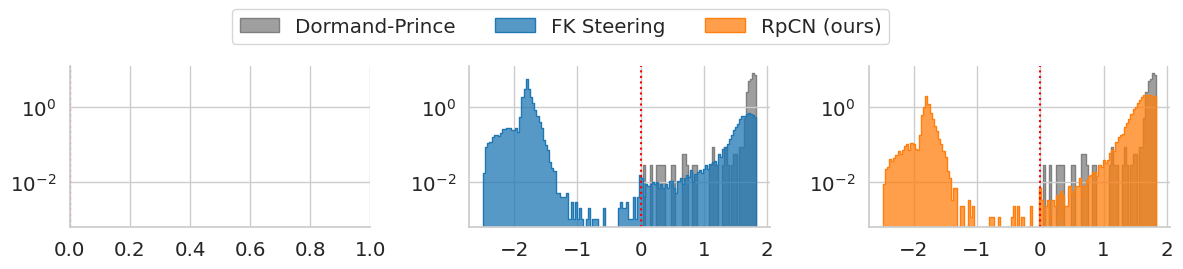

In [61]:
data = duckdb.sql("select alt_id, steering, constraint_value from metrics_unpivot").pl()
data = pl.concat((data, ground_truth), how='vertical')
data
bins = np.histogram(np.zeros(2), bins=128, range=(ground_truth_range['min'].item(), ground_truth_range['max'].item()))[1]
show_no_steering = False
if show_no_steering:
    order = ['NoSteering (EULER_MARUYAMA)', 'NoSteering (HEUN)']
else:
    order = ['GroundTruth', 'FeynmannKac', 'RpCN']
name_map = {
    'GroundTruth': 'Dormand-Prince',
    'NoSteering (EULER_MARUYAMA)': 'No steering (Euler-Maruyama)',
    'NoSteering (HEUN)': 'No steering (Heun)',
    'FeynmannKac': 'FK Steering',
    'SourceParallelTempering': 'SPT',
    'RpCN': 'RpCN (ours)',
}
common_kws = dict(
    stat='density',
    x='constraint_value',
    bins=bins,
    element='step',
)
include_legend = True
plot = (
    sns.displot(
        data=data.filter(pl.col('steering') != 'GroundTruth'),
        col='steering',
        col_order=order,
        hue='steering',
        hue_order=order,
        palette={
            'GroundTruth': 'tab:grey',
            'NoSteering (EULER_MARUYAMA)': 'tab:red',
            'NoSteering (HEUN)': 'tab:purple',
            'FeynmannKac': 'tab:blue',
            'SourceParallelTempering': 'tab:orange',
            'RpCN': 'tab:orange',
        },
        alpha=.75,
        common_norm=False,
        **common_kws,
        height=2.4,
        # height=3,
        # aspect=2.2,
        aspect=1.7,
        legend=include_legend,
        facet_kws=dict(
            sharex=False,
        ),
    )
    .set_titles('')
    .set(
        xlabel='', ylabel='',
        yscale='log' if dataset_name == 'FitzHughNagumo' else 'linear'
    )
)
if not show_no_steering:
    plot.map(
        sns.histplot,
        data=data.filter((pl.col('steering') == 'GroundTruth') & (pl.col('constraint_value') > 0)),
        color='tab:grey',
        **common_kws,
        zorder=-1,
    ).set_xlabels('').set_ylabels('')
if include_legend:
    sns.move_legend(
        plot,
        loc='upper center',
        labels=[name_map[n] for n in order],
        ncol=4,
        title='',
        bbox_to_anchor=(.400, 1.18),
        frameon=True,
        fancybox=True,
    )
for (row, col, hue), _ in plot.facet_data():
    ax = plot.axes[row][col]
    if show_no_steering and row == 0:
        sns.histplot(
            data=data.filter((pl.col('steering') == 'GroundTruth')),
            color='tab:grey',
            **common_kws,
            ax=ax,
            zorder=-1,
        )
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax.axvline(x=0, c='r', ls=':')
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.yaxis.set_tick_params(labelleft=True)
    if row <= len(plot.row_names) - 2:
        ax.set_xticklabels([])
        # ax.xaxis.set_visible(False)
plot.tight_layout()

In [21]:
userfm.plots.save_all_subfigures(plot, 'Histogram')

In [62]:
if include_legend:
    userfm.plots.save_legend(plot, 'Histogram')
plot.savefig('Histogram.pdf', format='pdf', bbox_inches='tight', pad_inches=.06)

In [57]:
print('Total Variation (all samples)')
ground_truth_hist = np.histogram(data.filter((pl.col('steering') == 'GroundTruth') & (pl.col('constraint_value') > 0))['constraint_value'], bins=bins, density=True)[0]
for steering in data['steering'].unique():
    print(steering)
    steering_hist = np.histogram(data.filter(steering=steering)['constraint_value'], bins=bins, density=True)[0]
    total_variation = 0.5 * np.abs(steering_hist - ground_truth_hist) * np.diff(bins)
    print(f'{total_variation.sum():.4f}')

Total Variation (all samples)
RpCN
0.6202
FeynmannKac
0.8553
GroundTruth
0.9662


In [58]:
print('KL divergence (all samples)')
ground_truth_hist = np.histogram(data.filter((pl.col('steering') == 'GroundTruth') & (pl.col('constraint_value') > 0))['constraint_value'], bins=bins)[0].astype(np.float64)
ground_truth_hist += 1e-8
ground_truth_hist = ground_truth_hist / ground_truth_hist.sum()
for steering in data['steering'].unique():
    print(steering)
    steering_hist = np.histogram(data.filter(steering=steering)['constraint_value'], bins=bins)[0].astype(np.float64)
    steering_hist += 1e-8
    steering_hist = steering_hist / steering_hist.sum()
    # total_variation = 0.5 * np.abs(steering_hist - ground_truth_hist)# * np.diff(bins)
    # print(f'{total_variation.sum():.4f}')
    kl_divergence = (ground_truth_hist * (np.log(ground_truth_hist) - np.log(steering_hist))).sum()
    print(kl_divergence)

KL divergence (all samples)
RpCN
1.0064466101909433
FeynmannKac
2.160526716450766
GroundTruth
3.3869247100371367
